::: {.sb-lesson-links}
[Exercises →](../exercises/build-a-decision-tree.ipynb)
[Quiz →](../quiz/quiz.qmd)
[All files of this section (zip)](../../files/05-trees-and-forests.zip)
:::

::: {.sb-downloads}
[Download this notebook](../downloads/lesson-workflow.ipynb){download="lesson-workflow.ipynb"}  
Data: [customers.csv](../downloads/data/customers.csv){download="customers.csv"}

Put the data files in a folder named `data` next to the notebook.
:::

Let's train a decision tree and a random forest on our customers dataset (predict whether a customer buys the product).

## What will you learn in this course? 🧐🧐
This lecture is a follow-along demo that will guide you through the steps of building decision trees / random forest models and evaluate them on actual data.

* Preprocessing
    * Training pipeline
    * Test pipeline
* Decision tree
    * Training with hyperparameter optimization
    * Performances
* Random forest
    * Training with hyperparameter optimization
    * Performances

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import  OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay, RocCurveDisplay
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning) # to avoid deprecation warnings

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
# colour palette of the course
pio.templates["course"] = go.layout.Template(
    layout_colorway=["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3", "#111111", "#999999"]
)
pio.templates.default = "plotly_white+course"


In [ ]:
# Import dataset
print("Loading dataset...")
dataset = pd.read_csv("../data/customers.csv")
print("...Done.")
print()

Loading dataset...
...Done.



In [ ]:
# Basic stats
print("Number of rows : {}".format(dataset.shape[0]))
print()

print("Display of dataset: ")
display(dataset.head())
print()

print("Basics statistics: ")
data_desc = dataset.describe(include='all')
display(data_desc)
print()

print("Percentage of missing values: ")
display(100*dataset.isnull().sum()/dataset.shape[0])


Number of rows : 400

Display of dataset: 


,Country,Age,Salary,Purchased
0,Germany,20.0,38500.0,No
1,Spain,33.0,32200.0,No
2,Italy,43.0,47900.0,No
3,Germany,62.0,54300.0,No
4,France,53.0,51800.0,Yes



Basics statistics: 


,Country,Age,Salary,Purchased
count,400,391.000000,400.000000,400
unique,4,NaN,NaN,2
top,France,NaN,NaN,No
freq,139,NaN,NaN,241
mean,NaN,42.437340,47013.500000,NaN
std,NaN,13.297408,14079.992301,NaN
min,NaN,20.000000,13000.000000,NaN
25%,NaN,31.000000,35800.000000,NaN
50%,NaN,43.000000,47250.000000,NaN
75%,NaN,54.000000,58150.000000,NaN



Percentage of missing values: 


Country      0.00
Age          2.25
Salary       0.00
Purchased    0.00
dtype: float64

## Preprocessing

In [ ]:
# Separate target variable Y from features X
print("Separating labels from features...")
target_variable = "Purchased"

X = dataset.drop(target_variable, axis = 1)
Y = dataset.loc[:,target_variable]

print("...Done.")
print()

print('Y : ')
print(Y.head())
print()
print('X :')
print(X.head())

Separating labels from features...
...Done.

Y : 
0     No
1     No
2     No
3     No
4    Yes
Name: Purchased, dtype: str

X :
   Country   Age   Salary
0  Germany  20.0  38500.0
1    Spain  33.0  32200.0
2    Italy  43.0  47900.0
3  Germany  62.0  54300.0
4   France  53.0  51800.0


In [ ]:
# Automatically detect names of numeric/categorical columns
numeric_features = []
categorical_features = []
for i,t in X.dtypes.items():
    if ('float' in str(t)) or ('int' in str(t)) :
        numeric_features.append(i)
    else :
        categorical_features.append(i)

print('Found numeric features ', numeric_features)
print('Found categorical features ', categorical_features)

Found numeric features  ['Age', 'Salary']
Found categorical features  ['Country']


In [ ]:
# Divide dataset Train set & Test set 
print("Dividing into train and test sets...")
# WARNING : don't forget stratify=Y for classification problems
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0, stratify = Y)
print("...Done.")
print()

Dividing into train and test sets...
...Done.





::: {.callout-tip title="No need to normalize the numeric features!"}
Decision trees are not sensitive at all to the scale of the input features. So, if you plan to use only decision-tree-based algorithms, you can just skip the standardization step! The model's convergence time won't be deteriorated, neither will the computation of the features' importances.
:::



In [ ]:
# Create pipeline for numeric features
numeric_transformer = SimpleImputer(strategy='mean') # missing values will be replaced by columns' mean

In [ ]:
# Create pipeline for categorical features
categorical_transformer = OneHotEncoder(drop='first') # no missing values in categorical data, so we only need the OHE

In [ ]:
# Use ColumnTransformer to make a preprocessor object that describes all the treatments to be done
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

In [ ]:
# Preprocessings on train set
print("Performing preprocessings on train set...")
print(X_train.head())
X_train = preprocessor.fit_transform(X_train)
print('...Done.')
print(X_train[0:5]) # MUST use this syntax because X_train is a numpy array and not a pandas DataFrame anymore
print()
# Label encoding
print("Encoding labels...")
print(Y_train.head())
encoder = LabelEncoder()
Y_train = encoder.fit_transform(Y_train)
print("...Done")
print(Y_train[0:5])

# Preprocessings on test set
print("Performing preprocessings on test set...")
print(X_test.head()) 
X_test = preprocessor.transform(X_test) # Don't fit again !! The test set is used for validating decisions
# we made based on the training set, therefore we can only apply transformations that were parametered using the training set.
# Otherwise this creates what is called a leak from the test set which will introduce a bias in all your results.
print('...Done.')
print(X_test[0:5,:]) # MUST use this syntax because X_test is a numpy array and not a pandas DataFrame anymore
print()
# Label encoding
print("Encoding labels...")
print(Y_test[0:5])
Y_test = encoder.transform(Y_test)
print("...Done")
print(Y_test[0:5])

Performing preprocessings on train set...
     Country   Age   Salary
76    France  44.0  44000.0
367  Germany  38.0  48900.0
255  Germany  65.0  64700.0
218    Italy  21.0  25200.0
195   France  48.0  55700.0
...Done.
[[4.40e+01 4.40e+04 0.00e+00 0.00e+00 0.00e+00]
 [3.80e+01 4.89e+04 1.00e+00 0.00e+00 0.00e+00]
 [6.50e+01 6.47e+04 1.00e+00 0.00e+00 0.00e+00]
 [2.10e+01 2.52e+04 0.00e+00 1.00e+00 0.00e+00]
 [4.80e+01 5.57e+04 0.00e+00 0.00e+00 0.00e+00]]

Encoding labels...
76      No
367     No
255    Yes
218     No
195    Yes
Name: Purchased, dtype: str
...Done
[0 0 1 0 1]
Performing preprocessings on test set...
     Country   Age   Salary
357  Germany  59.0  68000.0
228  Germany  46.0  61000.0
105  Germany  52.0  67300.0
115    Italy  41.0  49600.0
188  Germany  31.0  30200.0
...Done.
[[5.90e+01 6.80e+04 1.00e+00 0.00e+00 0.00e+00]
 [4.60e+01 6.10e+04 1.00e+00 0.00e+00 0.00e+00]
 [5.20e+01 6.73e+04 1.00e+00 0.00e+00 0.00e+00]
 [4.10e+01 4.96e+04 0.00e+00 1.00e+00 0.00e+00]
 [3.10e

## Decision tree
Let's train a decision tree (with hyperparameter optimization) and evaluate its performances :

### Training with hyperparameter optimization
For Decision trees, the hyperparameters that are important for overfitting are :

* min_samples_leaf
* min_samples_split
* max_depth

In what follows, you'll see an example of how to tune these hyperparameters with cross-validated grid search :

In [ ]:
# Perform grid search
print("Grid search...")
classifier = DecisionTreeClassifier()

# Grid of values to be tested
params = {
    'max_depth': [4, 6, 8, 10],
    'min_samples_leaf': [1, 2, 5],
    'min_samples_split': [2, 4, 8]
}
gridsearch = GridSearchCV(classifier, param_grid = params, cv = 3) # cv : the number of folds to be used for CV
gridsearch.fit(X_train, Y_train)
print("...Done.")
print("Best hyperparameters : ", gridsearch.best_params_)
print("Best validation accuracy : ", gridsearch.best_score_)

Grid search...


...Done.
Best hyperparameters :  {'max_depth': 4, 'min_samples_leaf': 5, 'min_samples_split': 2}
Best validation accuracy :  0.7970081702227708


### Performances

In [ ]:
# Predictions on training set
print("Predictions on training set...")
Y_train_pred = gridsearch.predict(X_train)
print("...Done.")
print(Y_train_pred)
print()

# It's also possible to get the probabilities estimated by the model:
print("Probabilities on training set...")
Y_train_proba = gridsearch.predict_proba(X_train)
print("...Done.")
print(Y_train_proba)
print()

Predictions on training set...
...Done.
[0 0 1 0 1 0 0 0 0 0 0 0 1 0 0 0 1 1 1 0 1 0 1 0 1 1 1 0 1 1 0 0 1 1 1 0 0
 0 0 0 0 1 0 1 1 0 1 0 1 0 1 0 0 0 0 0 1 0 0 0 1 1 1 0 1 0 1 0 0 0 1 1 1 0
 0 0 0 0 0 1 0 0 0 1 1 0 0 0 1 0 0 1 1 1 0 0 0 0 0 0 1 0 1 1 1 1 0 0 0 0 0
 1 1 1 0 0 0 1 0 0 0 0 1 0 0 1 0 1 1 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 1 0 0
 0 0 0 0 0 1 0 0 1 0 1 0 0 0 0 0 1 0 1 0 0 0 0 1 1 0 1 1 0 0 0 0 1 1 0 1 0
 0 0 1 1 1 1 0 1 0 0 0 0 1 1 0 0 1 0 0 1 0 1 0 1 0 0 0 1 0 1 1 0 0 1 0 1 0
 0 0 0 0 0 0 1 0 0 1 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 1 1
 0 0 0 1 0 0 1 0 0 0 0 1 1 1 1 1 0 1 0 1 0 0 0 1 0 1 1 1 0 0 1 0 0 1 0 0 1
 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 1 0 1 0]

Probabilities on training set...
...Done.
[[0.85       0.15      ]
 [0.85       0.15      ]
 [0.03333333 0.96666667]
 [1.         0.        ]
 [0.30769231 0.69230769]
 [0.85       0.15      ]
 [0.85       0.15      ]
 [0.625      0.375     ]
 [0.85       0.15      ]
 [0.93220339 0.06779661]
 [1.         0.  

In [ ]:
# Predictions on test set
print("Predictions on test set...")
Y_test_pred = gridsearch.predict(X_test)
print("...Done.")
print(Y_test_pred)
print()

# It's also possible to get the probabilities estimated by the model:
print("Probabilities on test set...")
Y_test_proba = gridsearch.predict_proba(X_test)
print("...Done.")
print(Y_test_proba)
print()

Predictions on test set...
...Done.
[1 0 1 1 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 1 0 1 1 0 0 1 0 0 0 0
 0 0 0 1 0 0 1 0 0 0 0 0 0 0 1 0 1 1 0 0 1 0 1 0 0 0 1 0 1 1 0 1 0 0 0 0 0
 1 0 0 0 0 0]

Probabilities on test set...
...Done.
[[0.03333333 0.96666667]
 [0.625      0.375     ]
 [0.15       0.85      ]
 [0.33333333 0.66666667]
 [0.93220339 0.06779661]
 [1.         0.        ]
 [0.375      0.625     ]
 [0.66666667 0.33333333]
 [0.375      0.625     ]
 [0.93220339 0.06779661]
 [0.85       0.15      ]
 [0.85       0.15      ]
 [0.93220339 0.06779661]
 [0.85       0.15      ]
 [0.85       0.15      ]
 [1.         0.        ]
 [0.85       0.15      ]
 [0.5625     0.4375    ]
 [0.93220339 0.06779661]
 [0.93220339 0.06779661]
 [0.03333333 0.96666667]
 [0.625      0.375     ]
 [0.5625     0.4375    ]
 [0.93220339 0.06779661]
 [0.93220339 0.06779661]
 [0.30769231 0.69230769]
 [0.03333333 0.96666667]
 [0.5625     0.4375    ]
 [0.03333333 0.96666667]
 [0.15       0.85      ]
 [1.       

In [ ]:
# Print scores
print("accuracy on training set : ", accuracy_score(Y_train, Y_train_pred))
print("accuracy on test set : ", accuracy_score(Y_test, Y_test_pred))
print()

print("f1-score on training set : ", f1_score(Y_train, Y_train_pred))
print("f1-score on test set : ", f1_score(Y_test, Y_test_pred))
print()

accuracy on training set :  0.859375
accuracy on test set :  0.7625

f1-score on training set :  0.8117154811715481
f1-score on test set :  0.6545454545454545



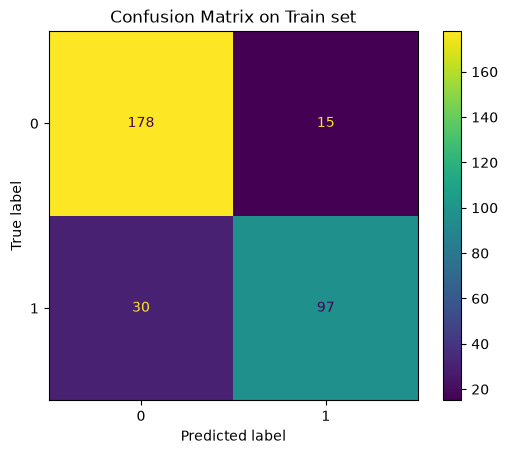

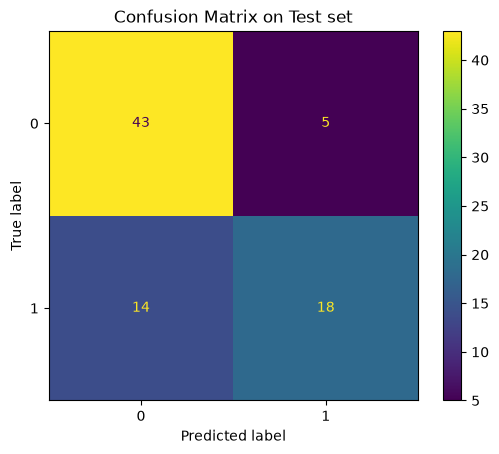

In [ ]:
# Visualize confusion matrices
_ , ax = plt.subplots() # Get subplot from matplotlib
ax.set(title="Confusion Matrix on Train set") # Set a title that we will add into ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(gridsearch, X_train, Y_train, ax=ax) # ConfusionMatrixDisplay from sklearn
plt.show()

_ , ax = plt.subplots() # Get subplot from matplotlib
ax.set(title="Confusion Matrix on Test set") # Set a title that we will add into ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(gridsearch, X_test, Y_test, ax=ax) # ConfusionMatrixDisplay from sklearn
plt.show()

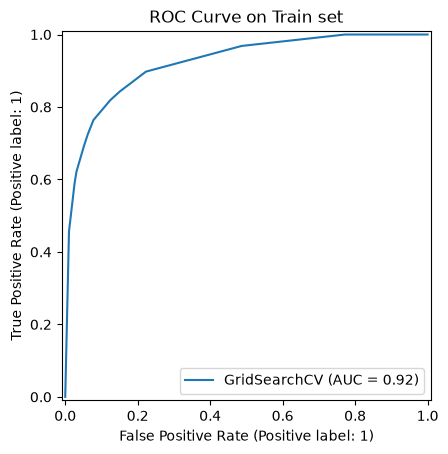

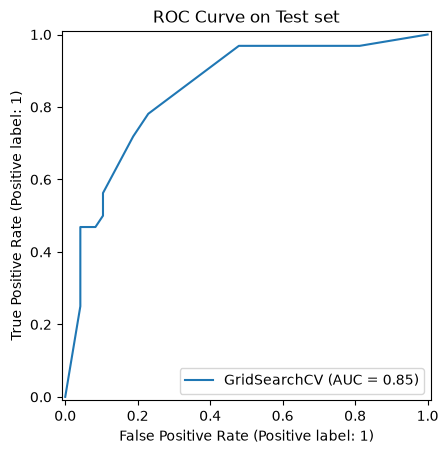

In [ ]:
# Visualize ROC curves
_ , ax = plt.subplots() # Get subplot from matplotlib
ax.set(title="ROC Curve on Train set") # Set a title that we will add into ConfusionMatrixDisplay
RocCurveDisplay.from_estimator(gridsearch, X_train, Y_train, ax=ax) # RocCurveDisplay from sklearn
plt.show()

_ , ax = plt.subplots() # Get subplot from matplotlib
ax.set(title="ROC Curve on Test set") # Set a title that we will add into ConfusionMatrixDisplay
RocCurveDisplay.from_estimator(gridsearch, X_test, Y_test, ax=ax) # RocCurveDisplay from sklearn
plt.show()

## Random Forest
Let's train a Random Forest (with hyperparameter optimization) and evaluate its performances :

### Training with hyperparameter optimization
For Random Forest, the hyperparameters that are important for overfitting are :

* min_samples_leaf
* min_samples_split
* max_depth
* n_estimators

In what follows, you'll see an example of how to tune these hyperparameters with cross-validated grid search :

In [ ]:
# Perform grid search
print("Grid search...")
classifier = RandomForestClassifier()

# Grid of values to be tested
params = {
    'max_depth': [2, 4, 6, 8, 10],
    'min_samples_leaf': [1, 2, 5],
    'min_samples_split': [2, 4, 8],
    'n_estimators': [10, 20, 40, 60, 80, 100]
}
gridsearch = GridSearchCV(classifier, param_grid = params, cv = 3) # cv : the number of folds to be used for CV
gridsearch.fit(X_train, Y_train)
print("...Done.")
print("Best hyperparameters : ", gridsearch.best_params_)
print("Best validation accuracy : ", gridsearch.best_score_)

Grid search...


...Done.
Best hyperparameters :  {'max_depth': 2, 'min_samples_leaf': 5, 'min_samples_split': 4, 'n_estimators': 100}
Best validation accuracy :  0.8344207370834068


### Performances

In [ ]:
# Predictions on training set
print("Predictions on training set...")
Y_train_pred = gridsearch.predict(X_train)
print("...Done.")
print(Y_train_pred)
print()

# It's also possible to get the probabilities estimated by the model:
print("Probabilities on training set...")
Y_train_proba = gridsearch.predict_proba(X_train)
print("...Done.")
print(Y_train_proba)
print()

Predictions on training set...
...Done.
[0 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 1 1 1 0 0 0 1 0 1 1 1 0 1 1 0 0 1 1 1 1 0
 0 0 0 0 1 0 1 1 0 1 1 1 0 1 0 0 0 0 0 0 0 0 1 1 1 1 0 1 0 1 1 0 0 0 1 1 0
 0 0 0 0 0 1 1 0 0 0 1 0 0 0 1 0 0 1 1 1 0 0 0 0 0 0 1 0 1 1 1 1 0 0 0 0 0
 1 0 1 0 0 0 1 0 0 0 0 1 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 1 1 0 0 1 0 0 1 0 0
 0 0 0 0 0 1 0 0 1 0 1 0 0 0 0 0 1 0 1 0 1 0 0 1 1 0 1 1 0 0 0 0 1 1 0 1 0
 0 0 1 0 1 1 0 1 0 0 0 0 1 1 0 0 1 0 0 1 0 1 0 1 1 1 0 1 0 1 1 0 0 1 0 1 0
 0 0 0 0 0 0 1 0 0 1 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 1 1
 0 0 0 1 0 0 1 0 0 0 0 1 0 1 1 1 0 1 1 1 0 0 0 1 0 1 1 0 0 0 1 0 0 1 0 0 1
 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 1 0 1 0]

Probabilities on training set...
...Done.
[[0.81026983 0.18973017]
 [0.81015289 0.18984711]
 [0.1481289  0.8518711 ]
 [0.87192257 0.12807743]
 [0.50596398 0.49403602]
 [0.84252464 0.15747536]
 [0.8293481  0.1706519 ]
 [0.48146469 0.51853531]
 [0.84252464 0.15747536]
 [0.85327855 0.14672145]
 [0.86471292 0.13

In [ ]:
# Predictions on test set
print("Predictions on test set...")
Y_test_pred = gridsearch.predict(X_test)
print("...Done.")
print(Y_test_pred)
print()

# It's also possible to get the probabilities estimated by the model:
print("Probabilities on test set...")
Y_test_proba = gridsearch.predict_proba(X_test)
print("...Done.")
print(Y_test_proba)
print()

Predictions on test set...
...Done.
[1 1 1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 1 1 0 0 1 0 0 0 0
 0 0 0 1 0 0 1 0 0 1 0 0 1 0 1 0 1 1 0 0 1 0 1 1 0 0 1 0 1 1 0 1 0 0 0 0 0
 1 0 0 0 0 0]

Probabilities on test set...
...Done.
[[0.14965432 0.85034568]
 [0.49624188 0.50375812]
 [0.18902141 0.81097859]
 [0.71277897 0.28722103]
 [0.85327855 0.14672145]
 [0.86471292 0.13528708]
 [0.26050325 0.73949675]
 [0.84252464 0.15747536]
 [0.22713061 0.77286939]
 [0.85131712 0.14868288]
 [0.81751171 0.18248829]
 [0.80447324 0.19552676]
 [0.85131712 0.14868288]
 [0.79036075 0.20963925]
 [0.83975724 0.16024276]
 [0.90505416 0.09494584]
 [0.79645967 0.20354033]
 [0.60924089 0.39075911]
 [0.85131712 0.14868288]
 [0.85131712 0.14868288]
 [0.16109525 0.83890475]
 [0.51906609 0.48093391]
 [0.68127837 0.31872163]
 [0.87848182 0.12151818]
 [0.85131712 0.14868288]
 [0.50156398 0.49843602]
 [0.14554879 0.85445121]
 [0.64073549 0.35926451]
 [0.08992335 0.91007665]
 [0.13732234 0.86267766]
 [0.9050541

In [ ]:
# Print scores
print("accuracy on training set : ", accuracy_score(Y_train, Y_train_pred))
print("accuracy on test set : ", accuracy_score(Y_test, Y_test_pred))
print()

print("f1-score on training set : ", f1_score(Y_train, Y_train_pred))
print("f1-score on test set : ", f1_score(Y_test, Y_test_pred))
print()

accuracy on training set :  0.8375
accuracy on test set :  0.8125

f1-score on training set :  0.7833333333333333
f1-score on test set :  0.7368421052631579



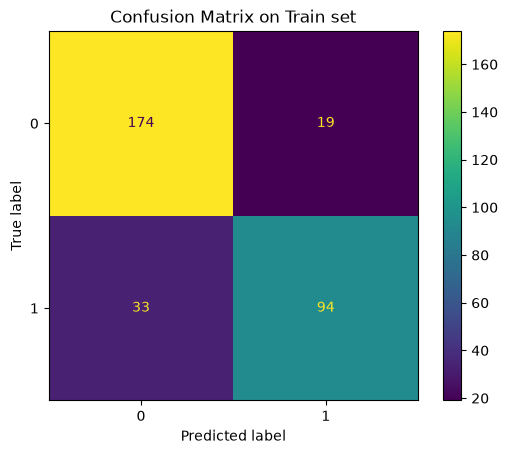

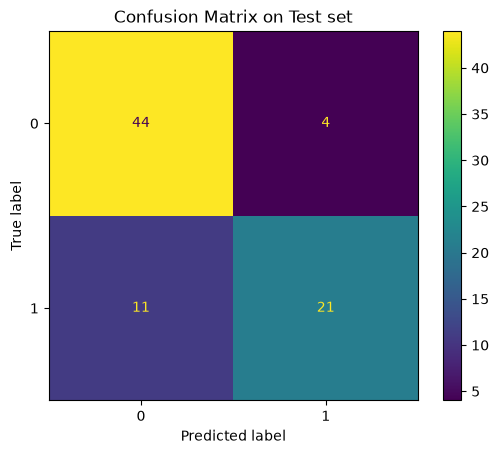

In [ ]:
# Visualize confusion matrices
_ , ax = plt.subplots() # Get subplot from matplotlib
ax.set(title="Confusion Matrix on Train set") # Set a title that we will add into ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(gridsearch, X_train, Y_train, ax=ax) # ConfusionMatrixDisplay from sklearn
plt.show()

_ , ax = plt.subplots() # Get subplot from matplotlib
ax.set(title="Confusion Matrix on Test set") # Set a title that we will add into ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(gridsearch, X_test, Y_test, ax=ax) # ConfusionMatrixDisplay from sklearn
plt.show()

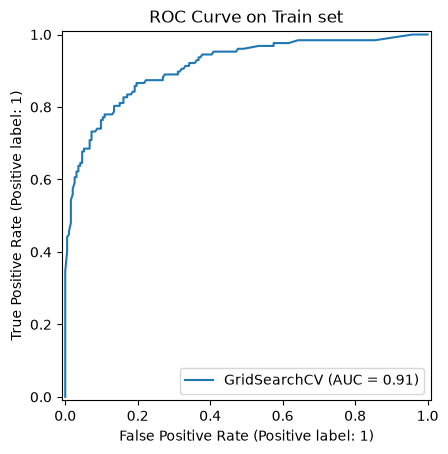

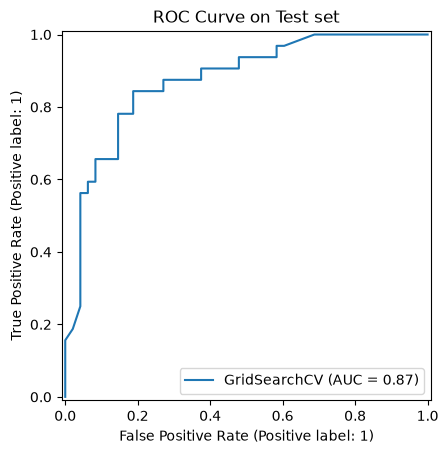

In [ ]:
# Visualize ROC curves
_ , ax = plt.subplots() # Get subplot from matplotlib
ax.set(title="ROC Curve on Train set") # Set a title that we will add into ConfusionMatrixDisplay
RocCurveDisplay.from_estimator(gridsearch, X_train, Y_train, ax=ax) # RocCurveDisplay from sklearn
plt.show()

_ , ax = plt.subplots() # Get subplot from matplotlib
ax.set(title="ROC Curve on Test set") # Set a title that we will add into ConfusionMatrixDisplay
RocCurveDisplay.from_estimator(gridsearch, X_test, Y_test, ax=ax) # RocCurveDisplay from sklearn
plt.show()

## Feature importance
All the classes from the module [sklearn.tree](https://scikit-learn.org/stable/modules/classes.html#module-sklearn.tree) have an attribute named `feature_importances_` that allows to get a ranking of the features once the model has been trained. Let's see an example of how to interpret these values obtained with the best `RandomForestClassifier`:

In [ ]:
column_names = []
for name, step, features_list in preprocessor.transformers_: # loop over steps of ColumnTransformer
    if name == 'num': # if pipeline is for numeric variables
        features = features_list # just get the names of columns to which it has been applied
    else: # if pipeline is for categorical variables
        features = step.get_feature_names_out() # get output columns names from OneHotEncoder
    column_names.extend(features) # concatenate features names
        
print("Names of columns corresponding to each coefficient: ", column_names)

Names of columns corresponding to each coefficient:  ['Age', 'Salary', 'Country_Germany', 'Country_Italy', 'Country_Spain']


In [ ]:
# Create a pandas DataFrame
feature_importance = pd.DataFrame(index = column_names, data = gridsearch.best_estimator_.feature_importances_, columns=["feature_importances"])
feature_importance = feature_importance.sort_values(by = 'feature_importances')

In [ ]:
# Plot coefficients
fig = px.bar(feature_importance, orientation = 'h')
fig.update_layout(showlegend = False, 
                  margin = {'l': 120} # to avoid cropping of column names
                 )
fig.show()

## Resources 📚📚

* [Decision trees in scikit-learn](https://scikit-learn.org/stable/modules/tree.html)

::: {.sb-next}
**[Next: Summary: decision trees →](../lessons/summary-decision-trees.ipynb)**
:::